# Learning rate { #sec-learning-rate }

This page covers the prior distributions, step size schedules, and regularization schedules available for use with SVGD inference.

In [1]:
from phasic import (
    Graph, with_ipv,
    GaussPrior, HalfCauchyPrior, DataPrior,
    ConstantStepSize, ExpStepSize, AdaptiveStepSize, WarmupExpStepSize,
    ConstantRegularization, ExpRegularization, ExponentialCDFRegularization,
    Adam, Adamelia,
    set_log_level, clear_caches,
)
import sys
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
import seaborn as sns
np.random.seed(42)
import vscodenb
import svgd_tests
sns.set_palette('tab10')
set_log_level('INFO')
clear_caches()

[INFO] phasic.graph_cache: Cleared 0 cached graphs


  Removed 2 file(s), preserved directory structure


In [2]:
nr_samples = 4

@with_ipv([nr_samples]+[0]*(nr_samples-1))
def coalescent_1param(state):
    transitions = []
    for i in range(state.size):
        for j in range(i, state.size):            
            same = int(i == j)
            if same and state[i] < 2:
                continue
            if not same and (state[i] < 1 or state[j] < 1):
                continue 
            new = state.copy()
            new[i] -= 1
            new[j] -= 1
            new[i+j+1] += 1
            transitions.append([new, [state[i]*(state[j]-same)/(1+same)]])
    return transitions

graph = Graph(coalescent_1param)
true_theta = [7]
graph.update_weights(true_theta)
observed_data = graph.sample(10000)

[INFO] phasic.graph_cache: Saved graph to cache: 4e7d3baaa4030c3c... (6 vertices)
[INFO] phasic: Saved graph to cache: 6 vertices


## Step size schedules

The step size (learning rate) controls how far particles move at each SVGD iteration. A step size that is too large causes oscillation; too small causes slow convergence. Schedules let you vary the step size over the course of optimization. Pass a schedule to `graph.svgd()` via the `learning_rate` parameter, or to an optimizer like `Adam(learning_rate=schedule)`.

### ConstantStepSize

The simplest schedule: the same step size at every iteration. This is also the implicit default when you pass a plain number as the `learning_rate`.

Step at iteration 0:   0.01
Step at iteration 500: 0.01


<Axes: title={'right': 'ConstantStepSize'}, xlabel='Iteration', ylabel='Step Size'>

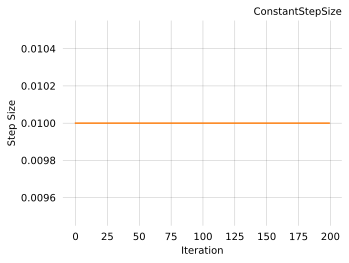

In [3]:
const = ConstantStepSize(0.01)
print(f"Step at iteration 0:   {const(0)}")
print(f"Step at iteration 500: {const(500)}")

const.plot(200)

Se the API documentation for `ConstantStepSize` for all parameters.

### ExpStepSize

Exponential decay from `first_step` to `last_step` with time constant `tau`:

$$
\eta(t) = \eta_0 \, e^{-t/\tau} + \eta_\infty \left(1 - e^{-t/\tau}\right)
$$

At $t = \tau$, roughly 63% of the decay has occurred. This is the most commonly used schedule — start with a large step to explore, then settle down for fine-tuning.

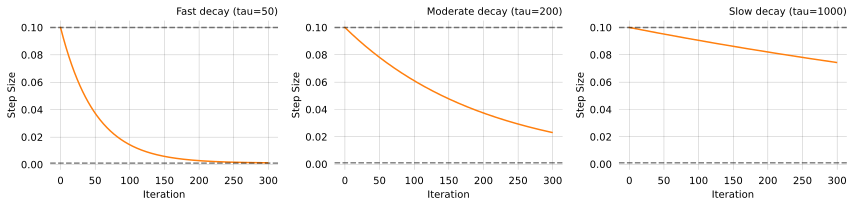

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

# Fast decay
s1 = ExpStepSize(first_step=0.1, last_step=0.001, tau=50.0)
s1.plot(300, ax=axes[0], return_ax=True)
axes[0].set_title('Fast decay (tau=50)')

# Moderate decay
s2 = ExpStepSize(first_step=0.1, last_step=0.001, tau=200.0)
s2.plot(300, ax=axes[1], return_ax=True)
axes[1].set_title('Moderate decay (tau=200)')

# Slow decay
s3 = ExpStepSize(first_step=0.1, last_step=0.001, tau=1000.0)
s3.plot(300, ax=axes[2], return_ax=True)
axes[2].set_title('Slow decay (tau=1000)')

plt.tight_layout()

Se the API documentation for `ExpStepSize` for all parameters.

### WarmupExpStepSize

A linear ramp-up phase followed by exponential decay. This is useful with Adam and other adaptive optimizers where moment estimates are poorly calibrated in the first few iterations — a warmup prevents large early updates.

$$
\eta(t) = \begin{cases}
\eta_{\text{peak}} \cdot \frac{t+1}{T_{\text{warmup}}} & t < T_{\text{warmup}} \\
\eta_{\text{peak}} \, e^{-(t - T_{\text{warmup}})/\tau} + \eta_\infty \left(1 - e^{-(t - T_{\text{warmup}})/\tau}\right) & t \geq T_{\text{warmup}}
\end{cases}
$$

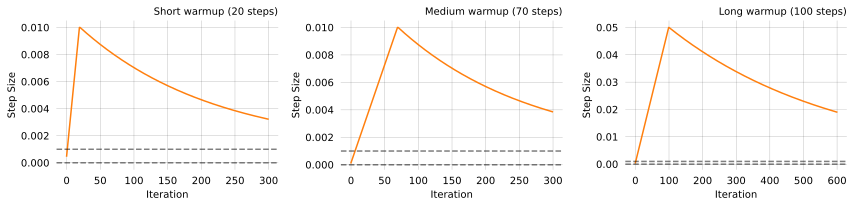

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

# Short warmup
w1 = WarmupExpStepSize(peak_lr=0.01, warmup_steps=20, last_lr=0.001, tau=200.0)
w1.plot(300, ax=axes[0], return_ax=True)
axes[0].set_title('Short warmup (20 steps)')

# Medium warmup
w2 = WarmupExpStepSize(peak_lr=0.01, warmup_steps=70, last_lr=0.001, tau=200.0)
w2.plot(300, ax=axes[1], return_ax=True)
axes[1].set_title('Medium warmup (70 steps)')

# Long warmup, high peak
w3 = WarmupExpStepSize(peak_lr=0.05, warmup_steps=100, last_lr=0.001, tau=500.0)
w3.plot(600, ax=axes[2], return_ax=True)
axes[2].set_title('Long warmup (100 steps)')

plt.tight_layout()

Se the API documentation for `WarmupExpStepSize` for all parameters.

### AdaptiveStepSize

Adjusts the step size dynamically based on particle spread. When particles are too concentrated the step size increases; when too dispersed it decreases. This is a simple heuristic that does not require tuning a decay schedule, but its behavior depends on the optimization trajectory (se the API documentation for `AdaptiveStepSize` for all parameters.).

In [6]:
adaptive = AdaptiveStepSize(base_step=0.01, kl_target=0.1, adjust_rate=0.1)
print(f"Base step: {adaptive.base_step}")
print(f"Without particles: {adaptive(0):.4f}")

# Simulate concentrated particles
concentrated = jnp.array([[1.0], [1.01], [0.99]])
print(f"Concentrated particles: {adaptive(1, concentrated):.4f} (increases)")

# Simulate spread particles
spread = jnp.array([[1.0], [10.0], [100.0]])
print(f"Spread particles: {adaptive(2, spread):.4f} (decreases)")

Base step: 0.01
Without particles: 0.0100
Concentrated particles: 0.0110 (increases)
Spread particles: 0.0099 (decreases)


### Comparison

All four schedules on the same axes for a 300-iteration run:

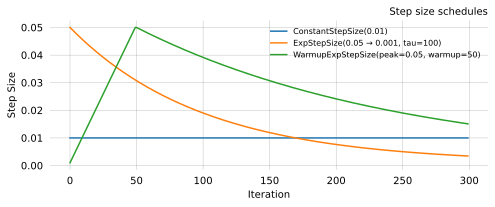

In [7]:
nr_iter = 300
iters = np.arange(nr_iter)

schedules = {
    'ConstantStepSize(0.01)': ConstantStepSize(0.01),
    'ExpStepSize(0.05 → 0.001, tau=100)': ExpStepSize(0.05, 0.001, 100.0),
    'WarmupExpStepSize(peak=0.05, warmup=50)': WarmupExpStepSize(0.05, 50, 0.001, 200.0),
}

fig, ax = plt.subplots(figsize=(7, 3))
for label, sched in schedules.items():
    vals = [float(sched(i)) for i in iters]
    ax.plot(iters, vals, label=label)

ax.set_xlabel('Iteration')
ax.set_ylabel('Step Size')
ax.set_title('Step size schedules')
ax.legend(fontsize=8)
plt.tight_layout()

## Adaptive optimizers

Phasic provides three optimizers for SVGD that offer adaptive per-parameter learning rates. These can be particularly useful when gradients have vastly different scales across parameters or when fixed step sizes cause oscillation.

#### Adam

When using `Adam`, the `learning_rate` parameter passed to SVGD is ignored in favor of the optimizer's learning rate.

`Adam` (Adaptive Moment Estimation) maintains running estimates of two quantities for each parameter:

1. **First moment ($m$)**: An exponentially weighted average of past gradients (momentum)
2. **Second moment ($v$)**: An exponentially weighted average of past squared gradients (gradient variance)

**Update rule:**

$$
\begin{align}
m &\leftarrow \beta_1 \cdot m + (1 - \beta_1) \cdot g \\
v &\leftarrow \beta_2 \cdot v + (1 - \beta_2) \cdot g^2 \\[0.5em]
\hat{m} &= \frac{m}{1 - \beta_1^t} \\[0.5em]
\hat{v} &= \frac{v}{1 - \beta_2^t} \\[0.5em]
\theta &\leftarrow \theta - \alpha \cdot \frac{\hat{m}}{\sqrt{\hat{v}} + \epsilon}
\end{align}
$$

Each parameter gets its own effective learning rate:

- Parameters with consistently large gradients $\rightarrow$ larger $\hat{v}$ $\rightarrow$ smaller effective step
- Parameters with consistently small gradients $\rightarrow$ smaller $\hat{v}$ $\rightarrow$ larger effective step

This automatic scaling helps when different parameters naturally have different gradient magnitudes.

When fixed learning rate works well:

- Well-behaved optimization landscapes
- Parameters with similar gradient scales
- When you've tuned the learning rate carefully

When Adam helps:

- Large datasets causing large gradient magnitudes
- Parameters with vastly different scales
- "Shark teeth" oscillation patterns in convergence
- When you want reasonable results without extensive tuning

Tuning Guidelines:

- learning_rate: Start with 0.001-0.01. If convergence is too slow, increase. If unstable, decrease.
- beta1: 0.9 works well for most cases. Lower values (0.8) give less momentum.
- beta2: 0.999 is standard. Lower values (0.99) adapt faster to gradient changes.
- epsilon: Rarely needs adjustment. Increase to 1e-7 if you see numerical issues.

Consider Adam when you observe:

- Oscillating convergence ("shark teeth" pattern in loss)
- Different parameters converging at different rates
- Sensitivity to learning rate choice
- Large datasets** causing large gradient magnitudes

Stick with fixed learning rate when:

- Convergence is already smooth and fast
- You've tuned the learning rate well for your problem
- You want minimal computational overhead
- The optimization landscape is well-behaved

[Kingma and Ba (2014)](https://arxiv.org/abs/1412.6980) - Adam: A Method for Stochastic Optimization. arXiv:1412.6980.



It can overcome even a misleading prior:

In [ ]:
optimizer = Adam(learning_rate=0.3)

svgd = graph.svgd(
    observed_data,
    prior = GaussPrior(ci=[5, 20]),
    n_particles=100,
    n_iterations=200,
    optimizer=optimizer,
)
svgd.summary()

Parameter  Fixed          MAP        Mean       SD         HPD 95% lo   HPD 95% hi  
0          No             7.045      7.042      0.1084     6.864        7.219       

Particles: 100, Iterations: 200


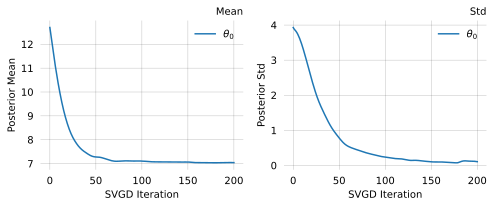

In [19]:
svgd.plot_convergence() ;

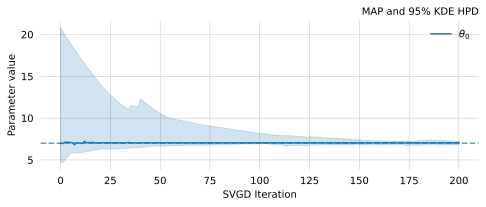

In [20]:
svgd.plot_ci(true_theta=true_theta) ;

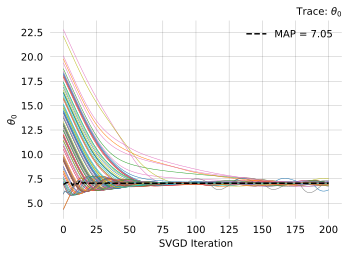

In [21]:
svgd.plot_trace() ;

In [22]:
#| echo: false
import pytest
if 'pytest' in sys.modules: svgd_tests.all(graph, true_theta, observed_data, svgd, rewards=None)

#### SGDMomentum

`SGDMomentum` (SGD with momentum) accumulates velocity in directions of persistent gradient descent, helping accelerate convergence and dampen oscillations. Update rule:

$$
\begin{align}
v &= m * v + g \\
\theta &= \theta + (l * v)
\end{align}
$$

where $g$ is gradient $l$ is learning rate, and $m$ and $v$ are the first and second moments.

```{.python}
from phasic.svgd import SGDMomentum

optimizer = SGDMomentum(
    learning_rate=0.01,  # Step size
    momentum=0.9         # Momentum coefficient (0.9 standard, 0.99 high)
)
svgd = graph.svgd(
    observed_data,
    prior = GaussPrior(ci=[5, 20]),
    n_particles=100,
    n_iterations=200,
    optimizer=optimizer,
)
svgd.summary()
```


#### RMSprop

`RMSprop` [(Hinton 2012)](https://www.cs.toronto.edu/~tijmen/csc321/slides/lecture_slides_lec6.pdf) divides the learning rate by an exponentially decaying average of squared gradients, adapting per-parameter. Update rule:

$$
\begin{align}

v &= d * v + (1 - d) * g^2 \\
\theta &= \theta + \frac{l * g}{\sqrt{v} + \epsilon}
\end{align}
$$

where $g$ is gradient $l$ is learning rate, $d$ is the decay and $v$ is 

```{.python}
from phasic.svgd import RMSprop

optimizer = RMSprop(
    learning_rate=0.05,  # Base learning rate (default 0.001)
    decay=0.99,       # Decay rate for squared gradient average
    epsilon=1e-8      # Numerical stability
)
svgd = graph.svgd(
    observed_data,
    prior = GaussPrior(ci=[5, 20]),
    n_particles=100,
    n_iterations=200,
    optimizer=optimizer,
)
svgd.summary()
```

#### Adagrad

`Adagrad` [(Duchi et al. 2011)](https://jmlr.org/papers/v12/duchi11a.html) accumulates the sum of squared gradients, giving smaller learning rates to parameters with large accumulated gradients. Update rule:

$$
\begin{align}
G &= g^2 \\
\theta &= \theta \frac{l * g}{\sqrt{G} + \epsilon}
\end{align}
$$

The learning rate of `Adagrad` decays over time as $G$ accumulates. For long runs, `RMSprop` or `Adam` may perform better.

```{.python}
from phasic import Adagrad

optimizer = Adagrad(
    learning_rate=0.5,  # Base learning rate (default 0.001)
    epsilon=1e-8         # Numerical stability
)
svgd = graph.svgd(
    observed_data,
    prior = GaussPrior(ci=[5, 20]),
    n_particles=100,
    n_iterations=200,
    optimizer=optimizer,
)
svgd.summary()
```

## Regularization schedules

Moment regularization adds a penalty term to the SVGD objective that encourages the model moments at the current parameter values to match the empirical moments. This is controlled by the `regularization` parameter in `graph.svgd()` and requires specifying `nr_moments`. Strong regularization early in optimization helps guide particles into a reasonable region; reducing it later lets the likelihood dominate for fine-tuning.

### ConstantRegularization

A fixed regularization strength throughout optimisation.

In [ ]:
const_reg = ConstantRegularization(1.0)
print(f"Strength at iteration 0:   {const_reg(0)}")
print(f"Strength at iteration 500: {const_reg(500)}")

const_reg.plot(200)

Se the API documentation for `ConstantRegularization` for all parameters.

### ExpRegularization

Exponential decay, identical in form to `ExpStepSize`:

$$
\lambda(t) = \lambda_0 \, e^{-t/\tau} + \lambda_\infty \left(1 - e^{-t/\tau}\right)
$$

Start with strong regularization to guide particles, then reduce to let the likelihood dominate.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

r1 = ExpRegularization(first_reg=10.0, last_reg=0.1, tau=30.0)
r1.plot(200, ax=axes[0], return_ax=True)
axes[0].set_title('Fast decay (tau=30)')

r2 = ExpRegularization(first_reg=10.0, last_reg=0.1, tau=100.0)
r2.plot(200, ax=axes[1], return_ax=True)
axes[1].set_title('Moderate decay (tau=100)')

r3 = ExpRegularization(first_reg=10.0, last_reg=0.1, tau=500.0)
r3.plot(200, ax=axes[2], return_ax=True)
axes[2].set_title('Slow decay (tau=500)')

plt.tight_layout()

Se the API documentation for `ExpRegularization` for all parameters.

### ExponentialCDFRegularization

Uses the exponential CDF for a smooth S-curve transition:

$$
\lambda(t) = \lambda_0 + (\lambda_\infty - \lambda_0) \left(1 - e^{-t/\tau}\right)
$$

This is mathematically equivalent to `ExpRegularization` for decreasing schedules, but the parameterisation makes it equally natural for *increasing* schedules — useful for progressive regularization where you start with pure likelihood and gradually add moment matching.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

# Decreasing (same as ExpRegularization)
c1 = ExponentialCDFRegularization(first_reg=5.0, last_reg=0.1, tau=100.0)
c1.plot(300, ax=axes[0], return_ax=True)
axes[0].set_title('Decreasing (5 → 0.1)')

# Increasing — start with likelihood only, add regularization later
c2 = ExponentialCDFRegularization(first_reg=0.0, last_reg=5.0, tau=100.0)
c2.plot(300, ax=axes[1], return_ax=True)
axes[1].set_title('Increasing (0 → 5)')

plt.tight_layout()

Se the API documentation for `ExponentialCDFRegularization` for all parameters.

### Comparison

In [ ]:
nr_iter = 300
iters = np.arange(nr_iter)

reg_schedules = {
    'Constant(1.0)': ConstantRegularization(1.0),
    'Exp(10 → 0.1, tau=50)': ExpRegularization(10.0, 0.1, 50.0),
    'ExpCDF(0 → 5, tau=100)': ExponentialCDFRegularization(0.0, 5.0, 100.0),
    'ExpCDF(5 → 0.1, tau=100)': ExponentialCDFRegularization(5.0, 0.1, 100.0),
}

fig, ax = plt.subplots(figsize=(7, 3))
for label, sched in reg_schedules.items():
    vals = [float(sched(i)) for i in iters]
    ax.plot(iters, vals, label=label)

ax.set_xlabel('Iteration')
ax.set_ylabel('Regularization Strength')
ax.set_title('Regularization schedules')
ax.legend(fontsize=8)
plt.tight_layout()

## Putting it together

A typical SVGD call combining priors and schedules:

In [ ]:
svgd = graph.svgd(
    data,
    prior=DataPrior(graph, data, sd=2.0),
    optimizer=Adam(
        learning_rate=ExpStepSize(first_step=0.1, last_step=0.01, tau=30.0),
    ),
    # regularization=ExpRegularization(first_reg=5.0, last_reg=0.1, tau=20.0),
    # nr_moments=2,
    n_iterations=200,
)
svgd.summary()
svgd.plot_convergence() ;